# Discovering Newton's law of gravitation with Genetic Programming

A planet orbiting the Sun is continuously subjected to a gravitational force, which causes it to accelerate towards the Sun. According to Newton's law of universal gravitation, the magnitude of this acceleration depends on the distance between the planet and the Sun, following an inverse-square relationship.

If we consider the motion in the $x-y$ plane (2D), the magnitude of the gravitational acceleration is

$$
|a| = \frac{1}{r^2},
$$

where $r = \sqrt{x^2 + y^2}$ is the distance between the planet and the Sun. Here, we are using dimensionless units and setting $GM=1$.

Our goal is to rediscover this simple relationship using `gplearn`'s `SymbolicRegressor`, as a way to check that we understand how to use its interface.

To do this, we will work in polar coordinates and generate pairs of values $(r, a_r)$, where $a_r$ is the radial component of the acceleration. Since gravity points towards the Sun, this component is negative:

$$
a_r = -\frac{1}{r^2}.
$$

By expressing the problem in terms of the distance $r$ alone, we turn it into a one-dimensional symbolic regression problem, since the radial acceleration depends only on \(r\), and not on the angular coordinate. This makes it a simple exercise focused mainly on understanding and using the `gplearn` interface.

In [116]:
import numpy as np
import matplotlib.pyplot as plt
from gplearn.genetic import SymbolicRegressor
import graphviz

We start by sampling random points in the space (in polar coordinate, assuming the Sun in $(0, 0)$), and computing the acceleration field on those points defined by our dimensionless Newton's law.

In [117]:
np.random.seed(42)

# Generate observations
n_samples = 300

r = np.random.uniform(0.7, 2.5, n_samples)
theta = np.random.uniform(0, 2*np.pi, n_samples)

# Newton's law (GM = 1)
a_r = -1 / r**2

# Dataset
X = r.reshape(-1, 1)
y = a_r

Let's visualize the points now (coupled one, $((r, \theta), a)$).

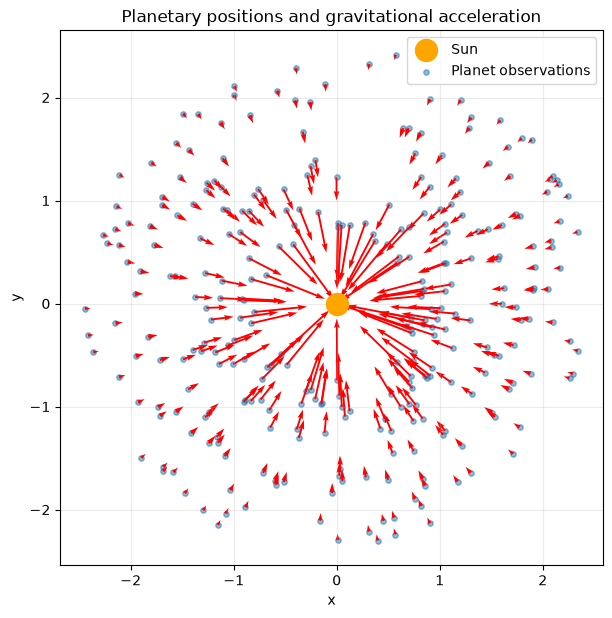

In [118]:
x = r * np.cos(theta)
y_pos = r * np.sin(theta)

fig, ax = plt.subplots(figsize=(7, 7))

ax.scatter(0, 0, s=250, color='orange', label='Sun', zorder=3)

ax.scatter(x, y_pos, s=15, alpha=0.5, label='Planet observations')

# Radial acceleration vectors
ax.quiver(
    x, y_pos,
    -x / r**3, -y_pos / r**3,
    color='red',
    angles='xy',
    scale_units='xy',
    scale=3
)

ax.set_aspect('equal')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('Planetary positions and gravitational acceleration')
ax.legend()
plt.show()

And finally let's simply use `gplearn` to fit a SymbolicRegressor over our data.

Define the parameter, fit the model and finally visualize the solution found with graphviz.

In [ ]:
# hyperparameters

In [ ]:
model = ...
# TODO
# model definition
# model fitting
# model visualization 

You can also run the cells below in order to visualize the acceleration field found and the discrepancy between the real Newtonian law and the one found by the SymbolicRegressor.

In [122]:
def visualize_discovery(model):

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    # Polar sampling grid
    r_grid = np.linspace(0.7, 2.5, 12)
    theta_grid = np.linspace(0, 2*np.pi, 24)

    R, THETA = np.meshgrid(r_grid, theta_grid)

    # Cartesian coordinates
    X_pos = R * np.cos(THETA)
    Y_pos = R * np.sin(THETA)

    # Model predictions
    R_flat = R.flatten()
    a_pred = model.predict(R_flat.reshape(-1, 1))

    # Convert radial acceleration into Cartesian components
    AX = (a_pred * np.cos(THETA.flatten())).reshape(R.shape)
    AY = (a_pred * np.sin(THETA.flatten())).reshape(R.shape)

    # Left: discovered gravitational field
    axes[0].quiver(X_pos, Y_pos, AX, AY, color='red', alpha=0.7)
    axes[0].scatter(0, 0, s=200, color='orange', edgecolor='black')

    axes[0].set_title('Discovered gravitational field')
    axes[0].set_aspect('equal')
    axes[0].set_xlabel('x')
    axes[0].set_ylabel('y')
    axes[0].grid(alpha=0.2)

    # Right: discovered radial acceleration law
    r_plot = np.linspace(0.7, 2.5, 200)

    axes[1].plot(r_plot, -1/r_plot**2, 'k--',
                 label='Newtonian law')
    axes[1].plot(
        r_plot,
        model.predict(r_plot.reshape(-1, 1)),
        'r',
        label='Discovered law'
    )

    axes[1].set_title('Radial acceleration')
    axes[1].set_xlabel('r')
    axes[1].set_ylabel('Acceleration')
    axes[1].legend()
    axes[1].grid(alpha=0.2)

    plt.tight_layout()
    plt.show()

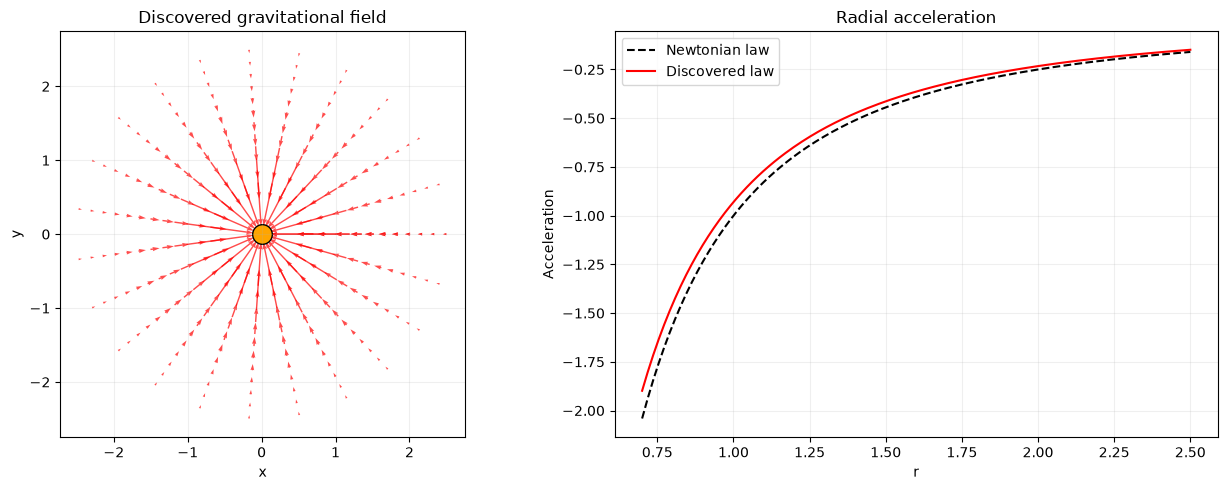

In [123]:
visualize_discovery(model)